# Phase 5: Clustering (K-Means Segmentation)

This notebook applies K-Means clustering to customer RFM features to identify distinct customer segments.

**Goals:**
- Load scaled RFM features
- Determine optimal number of clusters using Elbow Method
- Train K-Means model
- Assign cluster labels to customers
- Save segmented dataset
- Visualize clusters

**Tracking Milestone:**
✔ Load scaled RFM dataset
✔ Determine optimal number of clusters (Elbow Method)
✔ Train K-Means
✔ Save K-Means model to `/models/`
✔ Assign cluster labels
✔ Merge clusters back to RFM dataset
✔ Save final segmented dataset
✔ Create cluster visualizations in `/reports/figures/`

In [1]:
# Cell 1: Imports & Load Scaled RFM Data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
import pickle
import warnings
warnings.filterwarnings('ignore')

# Set style for better-looking plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Load scaled data
scaled_df = pd.read_csv("../data/processed/rfm_scaled.csv", index_col=0)
rfm_raw = pd.read_csv("../data/processed/rfm_raw.csv", index_col=0)

print("✓ Data loaded successfully")
print(f"\nScaled RFM shape: {scaled_df.shape}")
print(f"Raw RFM shape: {rfm_raw.shape}")
print(f"\nScaled RFM (first 5 rows):")
print(scaled_df.head())

✓ Data loaded successfully

Scaled RFM shape: (500, 3)
Raw RFM shape: (500, 4)

Scaled RFM (first 5 rows):
            Recency_scaled  Frequency_scaled  Monetary_scaled
CustomerID                                                   
12000            -0.951634         -0.974850        -0.649971
12001            -0.672354          0.654244         0.992023
12002             2.679008         -1.300668        -1.237919
12003             2.196615         -0.323212        -1.362979
12004             2.577451         -1.952306        -2.216558


ELBOW METHOD: Finding Optimal Number of Clusters
K=2: Inertia=848.92, Silhouette=0.4005
K=3: Inertia=602.84, Silhouette=0.3697
K=4: Inertia=486.98, Silhouette=0.3004
K=5: Inertia=415.64, Silhouette=0.3024
K=6: Inertia=367.11, Silhouette=0.2724
K=7: Inertia=329.05, Silhouette=0.2613
K=8: Inertia=296.28, Silhouette=0.2668
K=9: Inertia=278.00, Silhouette=0.2682
K=10: Inertia=257.63, Silhouette=0.2447


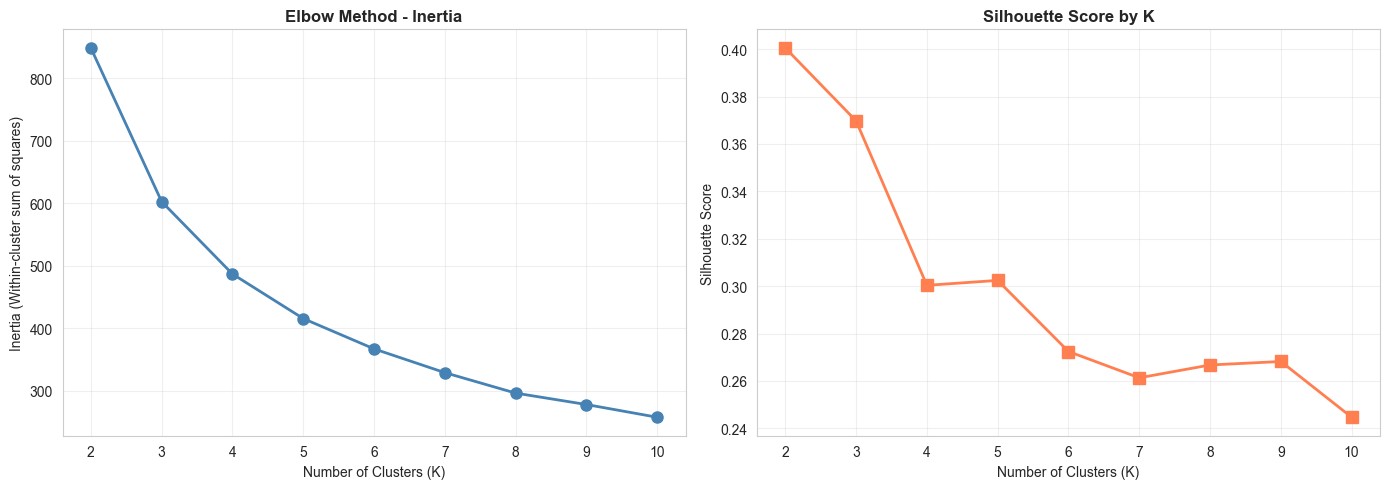


✓ Elbow method visualization saved to reports/figures/elbow_method.png

Recommendation: Choose K based on the elbow point (typically K=3, 4, or 5)


In [2]:
# Cell 2: Determine Optimal K (Elbow Method)

print("="*80)
print("ELBOW METHOD: Finding Optimal Number of Clusters")
print("="*80)

inertia_scores = []
silhouette_scores = []
from sklearn.metrics import silhouette_score

K = range(2, 11)

for k in K:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(scaled_df)
    inertia_scores.append(model.inertia_)
    sil_score = silhouette_score(scaled_df, labels)
    silhouette_scores.append(sil_score)
    print(f"K={k}: Inertia={model.inertia_:.2f}, Silhouette={sil_score:.4f}")

# Visualize Elbow Method
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Inertia plot
axes[0].plot(K, inertia_scores, marker='o', linewidth=2, markersize=8, color='steelblue')
axes[0].set_title('Elbow Method - Inertia', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia (Within-cluster sum of squares)')
axes[0].grid(True, alpha=0.3)

# Silhouette plot
axes[1].plot(K, silhouette_scores, marker='s', linewidth=2, markersize=8, color='coral')
axes[1].set_title('Silhouette Score by K', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../reports/figures/elbow_method.png", dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Elbow method visualization saved to reports/figures/elbow_method.png")
print("\nRecommendation: Choose K based on the elbow point (typically K=3, 4, or 5)")

In [3]:
# Cell 3: Train Final K-Means Model

# Based on elbow method, we'll use K=4 (common for customer segmentation)
# You can adjust this based on your elbow plot
k = 4

print(f"\nTraining K-Means with K={k}...")

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(scaled_df)

print(f"\n✓ K-Means model trained successfully")
print(f"\nCluster Centers (shape {kmeans.cluster_centers_.shape}):")
print(pd.DataFrame(
    kmeans.cluster_centers_,
    columns=["Recency_scaled", "Frequency_scaled", "Monetary_scaled"]
))
print(f"\nInertia: {kmeans.inertia_:.2f}")


Training K-Means with K=4...

✓ K-Means model trained successfully

Cluster Centers (shape (4, 3)):
   Recency_scaled  Frequency_scaled  Monetary_scaled
0       -0.315352         -0.994798        -1.217322
1       -0.370120          1.163057         0.931849
2        2.029501         -0.999164        -0.871137
3       -0.270024         -0.028424         0.220179

Inertia: 486.98


In [4]:
# Cell 4: Save the Trained Model

# Save K-Means model
with open("../models/kmeans_model.pkl", "wb") as f:
    pickle.dump(kmeans, f)

print("="*80)
print("MODEL SAVED")
print("="*80)
print(f"✓ K-Means model saved to: models/kmeans_model.pkl")
print(f"  • Clusters: {k}")
print(f"  • Features: 3 (Recency_scaled, Frequency_scaled, Monetary_scaled)")
print(f"  • Samples: {scaled_df.shape[0]}")
print(f"  • Random state: 42 (reproducible)")

MODEL SAVED
✓ K-Means model saved to: models/kmeans_model.pkl
  • Clusters: 4
  • Features: 3 (Recency_scaled, Frequency_scaled, Monetary_scaled)
  • Samples: 500
  • Random state: 42 (reproducible)


In [5]:
# Cell 5: Assign Cluster Labels

# Get cluster labels
cluster_labels = kmeans.labels_

# Add cluster to both dataframes
scaled_df["Cluster"] = cluster_labels
rfm_raw["Cluster"] = cluster_labels

print("="*80)
print("CLUSTER ASSIGNMENT")
print("="*80)
print(f"\nCluster distribution:")
print(rfm_raw["Cluster"].value_counts().sort_index())

print(f"\nPercentage distribution:")
print((rfm_raw["Cluster"].value_counts(normalize=True).sort_index() * 100).round(2))

print(f"\nRFM data with cluster labels (first 10 rows):")
print(rfm_raw.head(10))

CLUSTER ASSIGNMENT

Cluster distribution:
Cluster
0     98
1    146
2     67
3    189
Name: count, dtype: int64

Percentage distribution:
Cluster
0    19.6
1    29.2
2    13.4
3    37.8
Name: proportion, dtype: float64

RFM data with cluster labels (first 10 rows):
            Recency  Frequency      Monetary  Monetary_log  Cluster
CustomerID                                                         
12000             1          7   4120.286292      8.323921        0
12001            12         12   9248.846965      9.132362        1
12002           144          6   3084.418018      8.034442        2
12003           125          9   2900.167999      7.972869        2
12004           140          4   1904.703400      7.552606        2
12005             7          6   2183.040760      7.688932        0
12006            48         10   6462.272660      8.773891        3
12007            12         11   5035.839074      8.524534        3
12008            50         13  10552.449756      9.26

In [6]:
# Cell 6: Save Segmented Dataset

rfm_raw.to_csv("../data/processed/rfm_segmented.csv")
scaled_df.to_csv("../data/processed/rfm_scaled_with_clusters.csv")

print("="*80)
print("SEGMENTED DATA SAVED")
print("="*80)
print(f"\n✓ Segmented RFM dataset saved to: data/processed/rfm_segmented.csv")
print(f"  • Rows: {rfm_raw.shape[0]} customers")
print(f"  • Columns: {rfm_raw.shape[1]} (includes Cluster label)")
print(f"\n✓ Scaled data with clusters saved to: data/processed/rfm_scaled_with_clusters.csv")

SEGMENTED DATA SAVED

✓ Segmented RFM dataset saved to: data/processed/rfm_segmented.csv
  • Rows: 500 customers
  • Columns: 5 (includes Cluster label)

✓ Scaled data with clusters saved to: data/processed/rfm_scaled_with_clusters.csv



CLUSTER VISUALIZATIONS


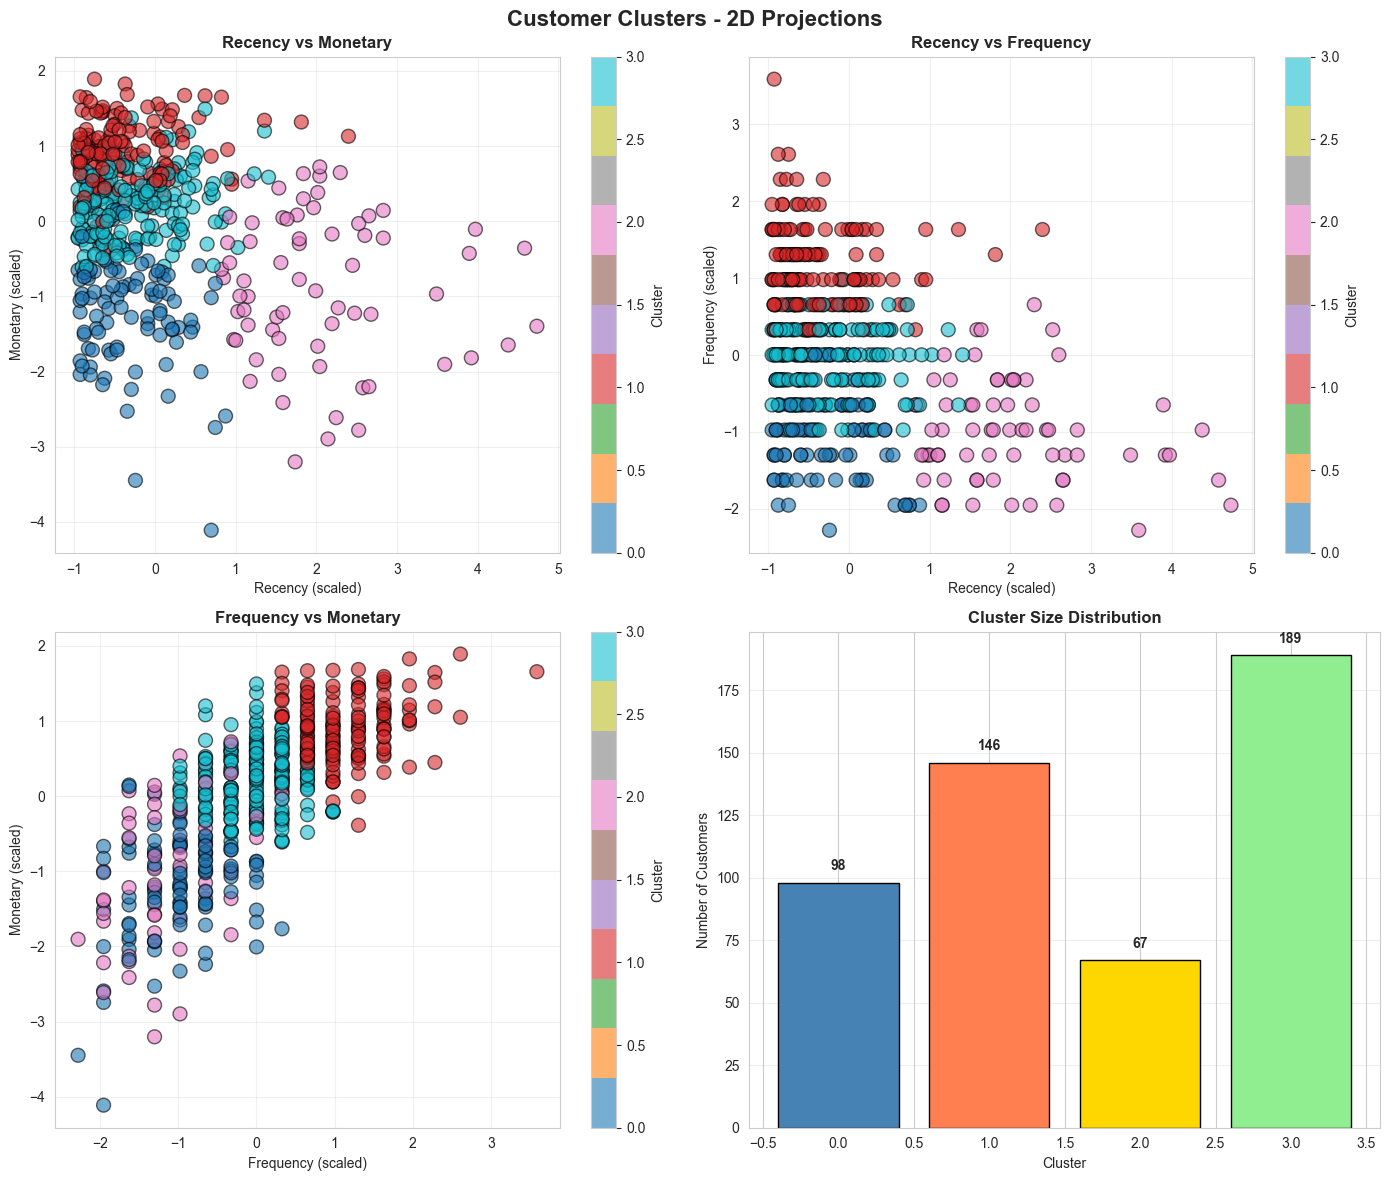


✓ Cluster scatter plots saved to reports/figures/cluster_scatter_plots.png


In [7]:
# Cell 7: Visualize Clusters (2D Scatter Plots)

print("\n" + "="*80)
print("CLUSTER VISUALIZATIONS")
print("="*80)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle('Customer Clusters - 2D Projections', fontsize=16, fontweight='bold')

# Recency vs Monetary (scaled)
scatter1 = axes[0, 0].scatter(
    scaled_df["Recency_scaled"],
    scaled_df["Monetary_scaled"],
    c=scaled_df["Cluster"],
    cmap="tab10",
    s=100,
    alpha=0.6,
    edgecolors='black'
)
axes[0, 0].set_title('Recency vs Monetary', fontweight='bold')
axes[0, 0].set_xlabel('Recency (scaled)')
axes[0, 0].set_ylabel('Monetary (scaled)')
axes[0, 0].grid(True, alpha=0.3)
plt.colorbar(scatter1, ax=axes[0, 0], label='Cluster')

# Recency vs Frequency (scaled)
scatter2 = axes[0, 1].scatter(
    scaled_df["Recency_scaled"],
    scaled_df["Frequency_scaled"],
    c=scaled_df["Cluster"],
    cmap="tab10",
    s=100,
    alpha=0.6,
    edgecolors='black'
)
axes[0, 1].set_title('Recency vs Frequency', fontweight='bold')
axes[0, 1].set_xlabel('Recency (scaled)')
axes[0, 1].set_ylabel('Frequency (scaled)')
axes[0, 1].grid(True, alpha=0.3)
plt.colorbar(scatter2, ax=axes[0, 1], label='Cluster')

# Frequency vs Monetary (scaled)
scatter3 = axes[1, 0].scatter(
    scaled_df["Frequency_scaled"],
    scaled_df["Monetary_scaled"],
    c=scaled_df["Cluster"],
    cmap="tab10",
    s=100,
    alpha=0.6,
    edgecolors='black'
)
axes[1, 0].set_title('Frequency vs Monetary', fontweight='bold')
axes[1, 0].set_xlabel('Frequency (scaled)')
axes[1, 0].set_ylabel('Monetary (scaled)')
axes[1, 0].grid(True, alpha=0.3)
plt.colorbar(scatter3, ax=axes[1, 0], label='Cluster')

# Cluster size bar chart
cluster_counts = rfm_raw["Cluster"].value_counts().sort_index()
axes[1, 1].bar(cluster_counts.index, cluster_counts.values, color=['steelblue', 'coral', 'gold', 'lightgreen'][:k], edgecolor='black')
axes[1, 1].set_title('Cluster Size Distribution', fontweight='bold')
axes[1, 1].set_xlabel('Cluster')
axes[1, 1].set_ylabel('Number of Customers')
axes[1, 1].grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for i, v in enumerate(cluster_counts.values):
    axes[1, 1].text(i, v + 5, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig("../reports/figures/cluster_scatter_plots.png", dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Cluster scatter plots saved to reports/figures/cluster_scatter_plots.png")

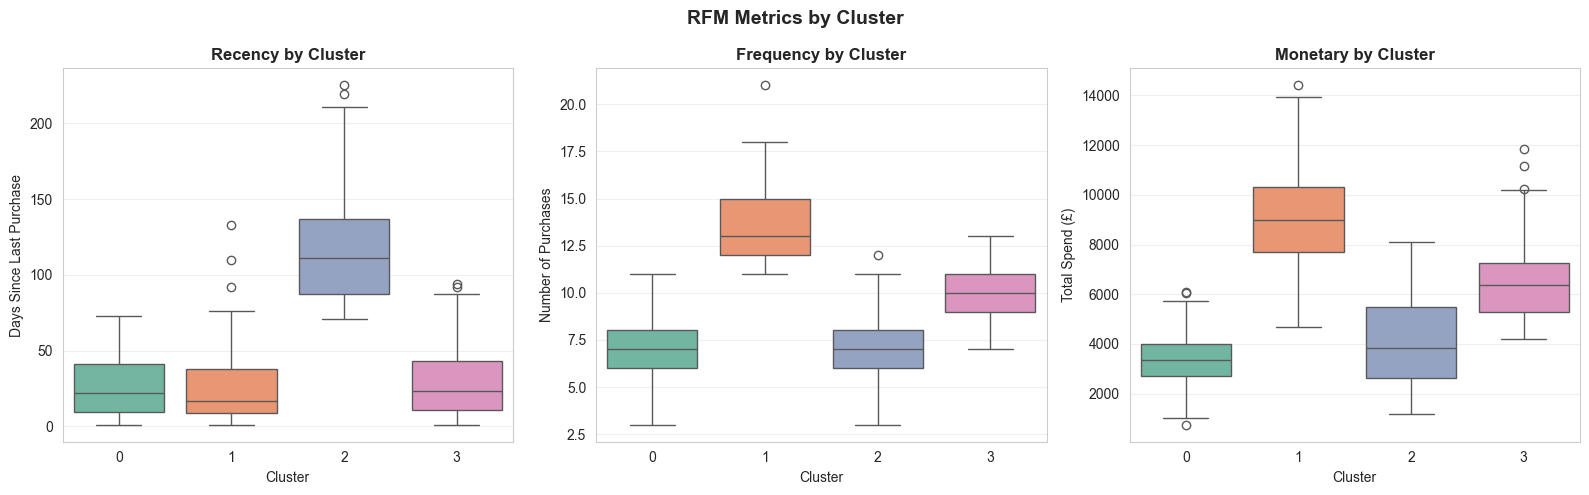

✓ Cluster boxplots saved to reports/figures/cluster_boxplots.png


In [8]:
# Cell 8: Cluster Characteristic Boxplots

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('RFM Metrics by Cluster', fontsize=14, fontweight='bold')

# Recency by cluster
sns.boxplot(data=rfm_raw, x="Cluster", y="Recency", ax=axes[0], palette="Set2")
axes[0].set_title('Recency by Cluster', fontweight='bold')
axes[0].set_ylabel('Days Since Last Purchase')
axes[0].grid(True, alpha=0.3, axis='y')

# Frequency by cluster
sns.boxplot(data=rfm_raw, x="Cluster", y="Frequency", ax=axes[1], palette="Set2")
axes[1].set_title('Frequency by Cluster', fontweight='bold')
axes[1].set_ylabel('Number of Purchases')
axes[1].grid(True, alpha=0.3, axis='y')

# Monetary by cluster
sns.boxplot(data=rfm_raw, x="Cluster", y="Monetary", ax=axes[2], palette="Set2")
axes[2].set_title('Monetary by Cluster', fontweight='bold')
axes[2].set_ylabel('Total Spend (£)')
axes[2].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig("../reports/figures/cluster_boxplots.png", dpi=300, bbox_inches='tight')
plt.show()

print("✓ Cluster boxplots saved to reports/figures/cluster_boxplots.png")

In [9]:
# Cell 9: Cluster Summary Statistics

print("\n" + "="*80)
print("CLUSTER SUMMARY STATISTICS")
print("="*80)

for cluster_id in sorted(rfm_raw["Cluster"].unique()):
    cluster_data = rfm_raw[rfm_raw["Cluster"] == cluster_id]
    
    print(f"\n{'─'*80}")
    print(f"CLUSTER {cluster_id} ({len(cluster_data)} customers, {len(cluster_data)/len(rfm_raw)*100:.1f}%)")
    print(f"{'─'*80}")
    
    print(f"\nRecency (days since last purchase):")
    print(f"  • Mean: {cluster_data['Recency'].mean():.1f} days")
    print(f"  • Median: {cluster_data['Recency'].median():.1f} days")
    print(f"  • Range: {cluster_data['Recency'].min()}-{cluster_data['Recency'].max()} days")
    
    print(f"\nFrequency (number of purchases):")
    print(f"  • Mean: {cluster_data['Frequency'].mean():.1f} purchases")
    print(f"  • Median: {cluster_data['Frequency'].median():.1f} purchases")
    print(f"  • Range: {cluster_data['Frequency'].min()}-{cluster_data['Frequency'].max()} purchases")
    
    print(f"\nMonetary (total spend):")
    print(f"  • Mean: £{cluster_data['Monetary'].mean():.2f}")
    print(f"  • Median: £{cluster_data['Monetary'].median():.2f}")
    print(f"  • Total: £{cluster_data['Monetary'].sum():,.2f}")
    print(f"  • Range: £{cluster_data['Monetary'].min():.2f} - £{cluster_data['Monetary'].max():.2f}")

print(f"\n{'─'*80}")


CLUSTER SUMMARY STATISTICS

────────────────────────────────────────────────────────────────────────────────
CLUSTER 0 (98 customers, 19.6%)
────────────────────────────────────────────────────────────────────────────────

Recency (days since last purchase):
  • Mean: 26.1 days
  • Median: 22.0 days
  • Range: 1-73 days

Frequency (number of purchases):
  • Mean: 6.9 purchases
  • Median: 7.0 purchases
  • Range: 3-11 purchases

Monetary (total spend):
  • Mean: £3282.87
  • Median: £3366.24
  • Total: £321,720.79
  • Range: £748.49 - £6106.30

────────────────────────────────────────────────────────────────────────────────
CLUSTER 1 (146 customers, 29.2%)
────────────────────────────────────────────────────────────────────────────────

Recency (days since last purchase):
  • Mean: 23.9 days
  • Median: 17.0 days
  • Range: 1-133 days

Frequency (number of purchases):
  • Mean: 13.6 purchases
  • Median: 13.0 purchases
  • Range: 11-21 purchases

Monetary (total spend):
  • Mean: £916

In [10]:
# Cell 10: Phase 5 Summary

print("\n" + "="*80)
print("PHASE 5 - CLUSTERING COMPLETED")
print("="*80)

print(f"""
✅ CLUSTERING MILESTONE COMPLETED

Model Training:
  ✓ K-Means trained with K={k} clusters
  ✓ Model saved to: models/kmeans_model.pkl
  ✓ Inertia: {kmeans.inertia_:.2f}

Customer Segmentation:
  ✓ {rfm_raw.shape[0]} customers assigned to clusters
  ✓ Segmented data saved to: data/processed/rfm_segmented.csv

Cluster Distribution:
""")

for cluster_id in sorted(rfm_raw["Cluster"].unique()):
    count = len(rfm_raw[rfm_raw["Cluster"] == cluster_id])
    pct = count / len(rfm_raw) * 100
    print(f"  • Cluster {cluster_id}: {count} customers ({pct:.1f}%)")

print(f"""
Visualizations Generated:
  ✓ Elbow method plot
  ✓ Cluster scatter plots (2D projections)
  ✓ Cluster boxplots
  ✓ All saved to: reports/figures/

✓ Ready for Phase 6: Cluster Interpretation & Persona Development
""")

print("="*80)
print("Ready for Phase 6: Business Insights & Customer Personas")
print("="*80)


PHASE 5 - CLUSTERING COMPLETED

✅ CLUSTERING MILESTONE COMPLETED

Model Training:
  ✓ K-Means trained with K=4 clusters
  ✓ Model saved to: models/kmeans_model.pkl
  ✓ Inertia: 486.98

Customer Segmentation:
  ✓ 500 customers assigned to clusters
  ✓ Segmented data saved to: data/processed/rfm_segmented.csv

Cluster Distribution:

  • Cluster 0: 98 customers (19.6%)
  • Cluster 1: 146 customers (29.2%)
  • Cluster 2: 67 customers (13.4%)
  • Cluster 3: 189 customers (37.8%)

Visualizations Generated:
  ✓ Elbow method plot
  ✓ Cluster scatter plots (2D projections)
  ✓ Cluster boxplots
  ✓ All saved to: reports/figures/

✓ Ready for Phase 6: Cluster Interpretation & Persona Development

Ready for Phase 6: Business Insights & Customer Personas
